### Задача B: Прогноз средней температуры на 7 дней

Вариант - 4, город для анализа - Якутск

In [ ]:

import json
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import urlopen

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from tensorflow.keras import Sequential, layers

SEED = 42
EPOCHS = 60
BATCH_SIZE = 32

HORIZON = 7          
MAX_WINDOW = 30     

tf.keras.utils.set_random_seed(SEED)

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

### 1.Загрузка данных
**Источник**: Open-Meteo Historical Weather API

**Период**: 2016-01-01 — 2025-12-31 (10 лет)

**Целевой показатель**: среднесуточная температура (temperature_2m_mean), °C

**Координаты Якутска**: 62.0355° с.ш., 129.6755° в.д.

Для того, чтобы не запрашивать API повторно, в коде кэшируем данные в CSV.

In [2]:
CITY = "Якутск"
LATITUDE = 62.0355
LONGITUDE = 129.6755

START_DATE = "2016-01-01"
END_DATE = "2025-12-31"

cache = Path(f"weather_{LATITUDE}_{LONGITUDE}_{START_DATE}_{END_DATE}.csv")

if cache.exists():
    df = pd.read_csv(cache, parse_dates=["date"])
else:
    params = {
        "latitude": LATITUDE,
        "longitude": LONGITUDE,
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "temperature_2m_mean",
        "timezone": "auto",
        "models": "era5",
    }
    url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(params)
    with urlopen(url, timeout=120) as response:
        data = json.load(response)

    df = pd.DataFrame(
        {
            "date": pd.to_datetime(data["daily"]["time"]),
            "temperature": data["daily"]["temperature_2m_mean"],
        }
    )
    df.to_csv(cache, index=False)

print("Город:", CITY)
print("Количество записей:", len(df))
display(df.head())

Город: Якутск
Количество записей: 3653


,date,temperature
0,2016-01-01,-39.9
1,2016-01-02,-33.9
2,2016-01-03,-33.2
3,2016-01-04,-37.4
4,2016-01-05,-35.8


### 2.Первичный анализ данных

Проверяем:
1. уникальность дат — дубликаты недопустимы для временного ряда.

2. непрерывность ряда: пропуска между датами быть не должно.

Если есть пропуски — описываем их, но НЕ интерполируем будущими значениями.

Повторяющихся дат: 0
Отсутствующих дат: 0
Пропусков температуры: 0


,temperature
count,3653.000000
mean,-6.963811
std,21.666668
min,-53.600000
25%,-27.900000
50%,-2.700000
75%,12.900000
max,27.900000


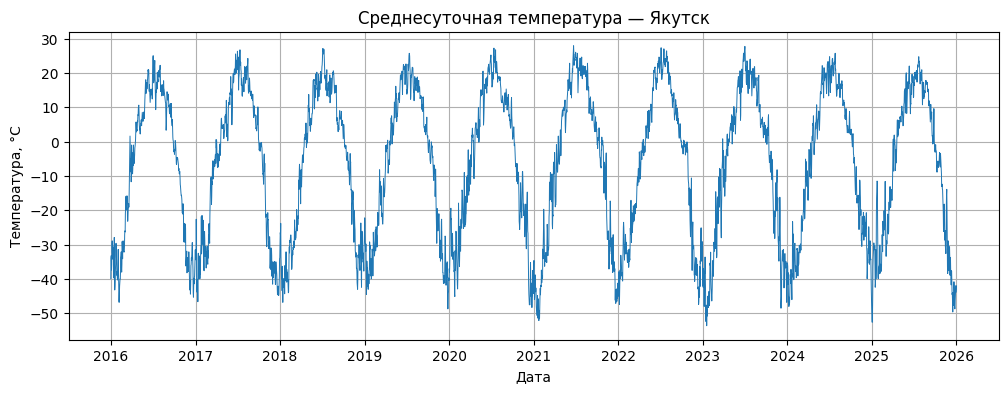

In [3]:
df = df.sort_values("date").reset_index(drop=True)

duplicates = df["date"].duplicated().sum()
print("Повторяющихся дат:", duplicates)

df = df.set_index("date")

expected_dates = pd.date_range(START_DATE, END_DATE, freq="D")
missing_dates = expected_dates.difference(df.index)
print("Отсутствующих дат:", len(missing_dates))

df = df.reindex(expected_dates)
df.index.name = "date"

print("Пропусков температуры:", df["temperature"].isna().sum())

display(df.describe())

plt.plot(df.index, df["temperature"], linewidth=0.7)
plt.title(f"Среднесуточная температура — {CITY}")
plt.xlabel("Дата")
plt.ylabel("Температура, °C")
plt.show()

График показывает ярко выраженную сезонность:
 - зимние минимумы до -50°C
 - летние максимумы до +25°C
 - годовая амплитуда ~75°C

Это важно: модель должна улавливать сезонный паттерн.

### 3.Масштабирование и разбиение

- Хронологическое разбиение: 70% / 15% / 15%
- ВАЖНО: без перемешивания (shuffle=False), иначе будет утечка данных из будущего
- scaler обучается ТОЛЬКО на train — иначе информация из test попадёт в модель
- Для интерпретации MAE и RMSE возвращаем значения к исходной шкале °C

In [4]:
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

temperature = df[["temperature"]].to_numpy(dtype=np.float32)

scaler = StandardScaler()
scaler.fit(temperature[:train_end])

scaled = scaler.transform(temperature).astype(np.float32)

splits = {
    "Train": (0, train_end),
    "Validation": (train_end, val_end),
    "Test": (val_end, n),
}

for name, (start, end) in splits.items():
    print(
        f"{name}: {df.index[start].date()} — "
        f"{df.index[end - 1].date()}, дней: {end - start}"
    )

Train: 2016-01-01 — 2022-12-31, дней: 2557
Validation: 2023-01-01 — 2024-07-01, дней: 548
Test: 2024-07-02 — 2025-12-31, дней: 548


### 4.Формирование окон


Функция ``make_windows_7day()`` формирует обучающие примеры методом скользящего окна (sliding window).

**Логика формирования:**
- **Вход X:** последовательность из `window` предыдущих дней `scaled[t-window : t]`
- **Целевое значение y:** среднее значение температуры за следующие 7 дней `mean(scaled[t : t+7])`

**Предотвращение утечки данных:**
Поскольку целевое окно охватывает 7 будущих дней, границы разбиения сдвигаются на `(HORIZON - 1)` дней назад:
- `safe_train_end = train_end - 6`
- `safe_val_end = val_end - 6`

Это гарантирует, что ни один обучающий пример не использует целевые значения из validation или test периодов.

**Результат:** Для каждого размера окна (7 и 30 дней) формируется словарь с тренировочными, валидационными и тестовыми выборками, а также соответствующие даты для тестового периода.

In [ ]:
def make_windows_7day(window):

    target_positions = np.arange(MAX_WINDOW, len(scaled) - HORIZON + 1)

    X = np.array([scaled[i - window : i] for i in target_positions], dtype=np.float32,)

    y = np.array([scaled[i : i + HORIZON].mean() for i in target_positions], dtype=np.float32, )

    target_end_positions = target_positions + HORIZON - 1

    train_mask = target_end_positions < train_end

    val_mask = ((target_positions >= train_end) & (target_end_positions < val_end))

    test_mask = (
        (target_positions >= val_end)
        & (target_end_positions < len(scaled))
    )
    return {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "X_val": X[val_mask],
        "y_val": y[val_mask],
        "X_test": X[test_mask],
        "y_test": y[test_mask],
        "test_dates": df.index[target_positions[test_mask]],
    }


datasets_7day = {window: make_windows_7day(window) for window in [7, 30]}

for window, dataset in datasets_7day.items():
    print(
        f"Окно {window}: "
        f"train {dataset['X_train'].shape}, "
        f"validation {dataset['X_val'].shape}, "
        f"test {dataset['X_test'].shape}"
    )

Окно 7: train (2521, 7, 1), validation (542, 7, 1), test (542, 7, 1)
Окно 30: train (2521, 30, 1), validation (542, 30, 1), test (542, 30, 1)


### 5.Построение моделей

**Архитектуры:**
1. MLP — базовая полносвязная сеть, вход Flatten(L, 1) → Dense → Dense(1)
2. SimpleRNN — один рекуррентный слой
3. LSTM — ячейки с механизмом забывания/сохранения
4. StackedLSTM — два LSTM-слоя, первый с return_sequences=True

**Выходная активация:** linear (регрессия непрерывной температуры).

**Функция потерь:** MSE

In [6]:
def build_model(kind, window, units, dropout, optimizer_name):
    model = Sequential([layers.Input(shape=(window, 1))])

    if kind == "MLP":
        model.add(layers.Flatten())
        model.add(layers.Dense(units, activation="relu"))

    elif kind == "SimpleRNN":
        model.add(layers.SimpleRNN(units))

    elif kind == "LSTM":
        model.add(layers.LSTM(units))

    elif kind == "StackedLSTM":
        model.add(layers.LSTM(units, return_sequences=True))
        model.add(layers.Dropout(dropout))
        model.add(layers.LSTM(units))

    else:
        raise ValueError(f"Неизвестная архитектура: {kind}")

    model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1))

    if optimizer_name == "Adam":
        optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
    elif optimizer_name == "RMSprop":
        optimizer = tf.keras.optimizers.RMSprop(learning_rate=0.001)
    else:
        raise ValueError("Неизвестный оптимизатор")

    model.compile(optimizer=optimizer, loss="mse")
    return model

### 6.Эксперименты

План экспериментов:
 - Длина окна L: 7 и 30 дней (сравнение короткого и длинного контекста)
 - Число нейронов: 32 и 64
 - Dropout: 0.0 и 0.2 (проверка регуляризации)
 - Оптимизатор: Adam и RMSprop

``EarlyStopping`` с ``patience=8`` — останавливаем обучение, если validation loss не улучшается 8 эпох подряд

``restore_best_weights=True`` — возвращаем веса лучшей эпохи

``shuffle=False`` — сохраняем хронологический порядок внутри batch

In [ ]:
configs = [
    (7, 32, 0.0, "Adam"),
    (30, 32, 0.0, "Adam"),
    (7, 64, 0.0, "Adam"),
    (7, 32, 0.2, "Adam"),
    (7, 32, 0.0, "RMSprop"),
]

kinds = ["MLP", "SimpleRNN", "LSTM", "StackedLSTM"]

experiments_7day = []
best_models_7day = {}

for kind in kinds:
    best_mae = np.inf

    for window, units, dropout, optimizer in configs:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        dataset = datasets_7day[window]

        model = build_model(kind, window, units, dropout, optimizer)

        stopping = tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=8,
            restore_best_weights=True,
        )

        history = model.fit(
            dataset["X_train"],
            dataset["y_train"],
            validation_data=(dataset["X_val"], dataset["y_val"]),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[stopping],
            shuffle=False,
            verbose=0,
        )

        val_prediction = scaler.inverse_transform(model.predict(dataset["X_val"], verbose=0)).ravel()
        val_true = scaler.inverse_transform(dataset["y_val"].reshape(-1, 1)).ravel()

        val_mae = mean_absolute_error(val_true, val_prediction)

        row = {
            "Модель": kind,
            "Окно": window,
            "Нейроны": units,
            "Dropout": dropout,
            "Оптимизатор": optimizer,
            "Эпох": len(history.history["loss"]),
            "Лучшая эпоха": int(np.argmin(history.history["val_loss"])) + 1,
            "Validation MAE": val_mae,
        }

        experiments_7day.append(row)

        if val_mae < best_mae:
            best_mae = val_mae
            best_models_7day[kind] = {
                "config": row.copy(),
                "weights": model.get_weights(),
                "history": history.history,
            }

        print(
            f"{kind}, окно={window}, нейроны={units}, "
            f"dropout={dropout}, {optimizer}: "
            f"validation MAE={val_mae:.3f} °C"
        )

experiment_table_7day = pd.DataFrame(experiments_7day)
display(experiment_table_7day.sort_values(["Модель", "Validation MAE"]))


MLP, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=3.626 °C
MLP, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=3.669 °C
MLP, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=3.577 °C
MLP, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=3.610 °C
MLP, окно=7, нейроны=32, dropout=0.0, RMSprop: validation MAE=3.737 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=3.613 °C
SimpleRNN, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=3.264 °C
SimpleRNN, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=3.620 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=3.607 °C
SimpleRNN, окно=7, нейроны=32, dropout=0.0, RMSprop: validation MAE=3.689 °C
LSTM, окно=7, нейроны=32, dropout=0.0, Adam: validation MAE=3.640 °C
LSTM, окно=30, нейроны=32, dropout=0.0, Adam: validation MAE=3.311 °C
LSTM, окно=7, нейроны=64, dropout=0.0, Adam: validation MAE=3.610 °C
LSTM, окно=7, нейроны=32, dropout=0.2, Adam: validation MAE=3.711 °C
LSTM

,Модель,Окно,Нейроны,Dropout,Оптимизатор,Эпох,Лучшая эпоха,Validation MAE
11,LSTM,30,32,0.0,Adam,60,60,3.310874
12,LSTM,7,64,0.0,Adam,60,60,3.609939
10,LSTM,7,32,0.0,Adam,60,60,3.639508
13,LSTM,7,32,0.2,Adam,60,60,3.710942
14,LSTM,7,32,0.0,RMSprop,60,54,3.718608
2,MLP,7,64,0.0,Adam,59,51,3.577309
3,MLP,7,32,0.2,Adam,60,60,3.610005
0,MLP,7,32,0.0,Adam,60,59,3.625514
1,MLP,30,32,0.0,Adam,30,22,3.669164
4,MLP,7,32,0.0,RMSprop,52,44,3.737225


### 7.Метрики и базовые прогнозы

Базовые прогнозы:
1. Naive (Persistence): T(t+1) = T(t) — прогноз = последнее известное значение
2. SeasonalNaive: T(t+1) = T(t-365) — значение год назад (для Якутска с его резкой сезонностью это сильный baseline)

Метрики считаем в исходной шкале °C (обратное масштабирование через ``scaler.inverse_transform``).

MAE и RMSE — в °C, MSE — в °C², R² — безразмерная (ориентир ≥ 0.80).

In [ ]:
def calculate_metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(actual, predicted),
    }


test_dates_7day = datasets_7day[7]["test_dates"]

actual_7day = np.array(
    [
        df.loc[t : t + pd.Timedelta(days=HORIZON - 1), "temperature"].mean()
        for t in test_dates_7day
    ]
)

predictions_7day = {}
results_7day = []

winner_7day = min(
    best_models_7day,
    key=lambda k: best_models_7day[k]["config"]["Validation MAE"],
)

for kind, saved in best_models_7day.items():
    config = saved["config"]
    dataset = datasets_7day[config["Окно"]]

    model = build_model(
        kind,
        config["Окно"],
        config["Нейроны"],
        config["Dropout"],
        config["Оптимизатор"],
    )
    model.set_weights(saved["weights"])

    predicted_scaled = model.predict(dataset["X_test"], verbose=0)
    predicted = scaler.inverse_transform(predicted_scaled).ravel()

    predictions_7day[kind] = predicted
    results_7day.append(
        {
            "Модель": kind,
            **calculate_metrics(actual_7day, predicted),
        }
    )


predictions_7day["Naive"] = np.array([
    df.loc[
        t - pd.Timedelta(days=HORIZON):
        t - pd.Timedelta(days=1),
        "temperature"
    ].mean()
    for t in test_dates_7day
])

predictions_7day["SeasonalNaive"] = np.array(
    [
        df.loc[
            t - pd.DateOffset(years=1) : t
            - pd.DateOffset(years=1)
            + pd.Timedelta(days=HORIZON - 1),
            "temperature",
        ].mean()
        for t in test_dates_7day
    ]
)

for name in ["Naive", "SeasonalNaive"]:
    if not np.isfinite(predictions_7day[name]).all():
        raise ValueError(f"Недостаточно данных для {name}")
    results_7day.append(
        {
            "Модель": name,
            **calculate_metrics(actual_7day, predictions_7day[name]),
        }
    )

result_table_7day = pd.DataFrame(results_7day).set_index("Модель")
display(result_table_7day.round(3))

print("Лучшая нейросеть по validation (7-day):", winner_7day)

,MAE,MSE,RMSE,R2
Модель,,,,
MLP,3.349,19.957,4.467,0.953
SimpleRNN,3.123,17.889,4.230,0.958
LSTM,3.145,17.823,4.222,0.958
StackedLSTM,3.134,17.310,4.160,0.959
Naive,3.904,26.563,5.154,0.938
SeasonalNaive,3.958,28.674,5.355,0.933


Лучшая нейросеть по validation (7-day): SimpleRNN


### 8.Графики

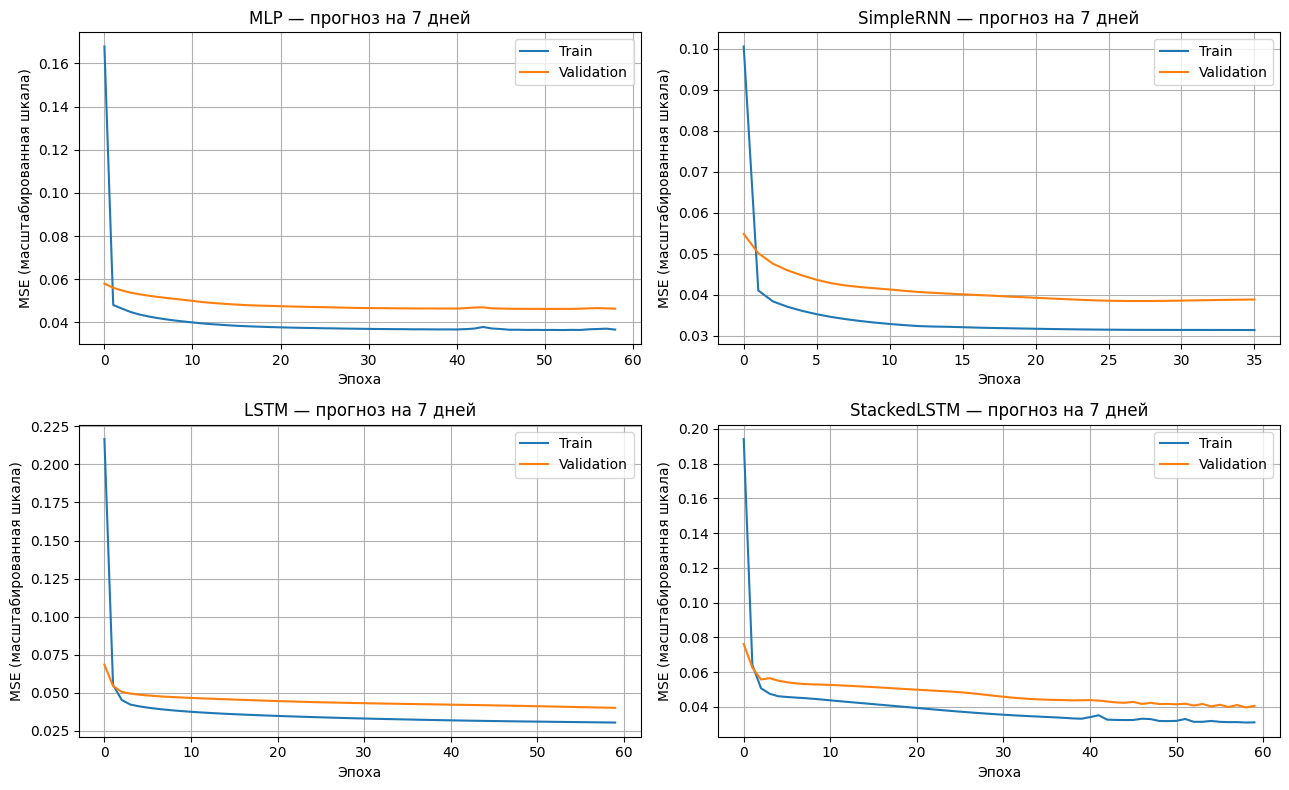

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, kind in zip(axes.ravel(), kinds):
    history = best_models_7day[kind]["history"]
    ax.plot(history["loss"], label="Train")
    ax.plot(history["val_loss"], label="Validation")
    ax.set_title(f"{kind} — прогноз на 7 дней")
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("MSE (масштабированная шкала)")
    ax.legend()

plt.tight_layout()
plt.show()

Графики выше - **кривые обучения (learning curves)** для каждой из четырёх нейросетевых архитектур на задаче прогноза средней температуры на 7 дней. Они показывают, как меняется ошибка модели в процессе обучения.

Линия Train (синяя) — ошибка на обучающей выборке (то, на чём модель учится).
Линия Validation (оранжевая) — ошибка на валидационной выборке (то, на чём модель НЕ учится, но проверяется).

По графикам видно, что:
1. **SimpleRNN** демонстрирует наиболее стабильное и эффективное обучение. Обе кривые быстро и плавно снижаются, сходясь к минимальному значению уже к 10–15 эпохе. Минимальный разрыв между ними говорит об отсутствии переобучения и отличной способности модели к обобщению.
2. **MLP** показывает «шумную» кривую валидации с заметными колебаниями. Это типично для полносвязных сетей при работе с временными рядами: без рекуррентных связей модели сложнее плавно улавливать сезонные зависимости, из-за чего процесс оптимизации становится менее стабильным.
3. **LSTM** и **StackedLSTM** обучаются очень плавно, однако между кривыми обучения и валидации сохраняется заметный разрыв, который к концу обучения немного увеличивается. Это указывает на лёгкое переобучение — сложные рекуррентные архитектуры начинают «запоминать» шум обучающей выборки. Тем не менее, валидационная ошибка не растёт, а выходит на плато, что говорит о хорошем контроле качества.

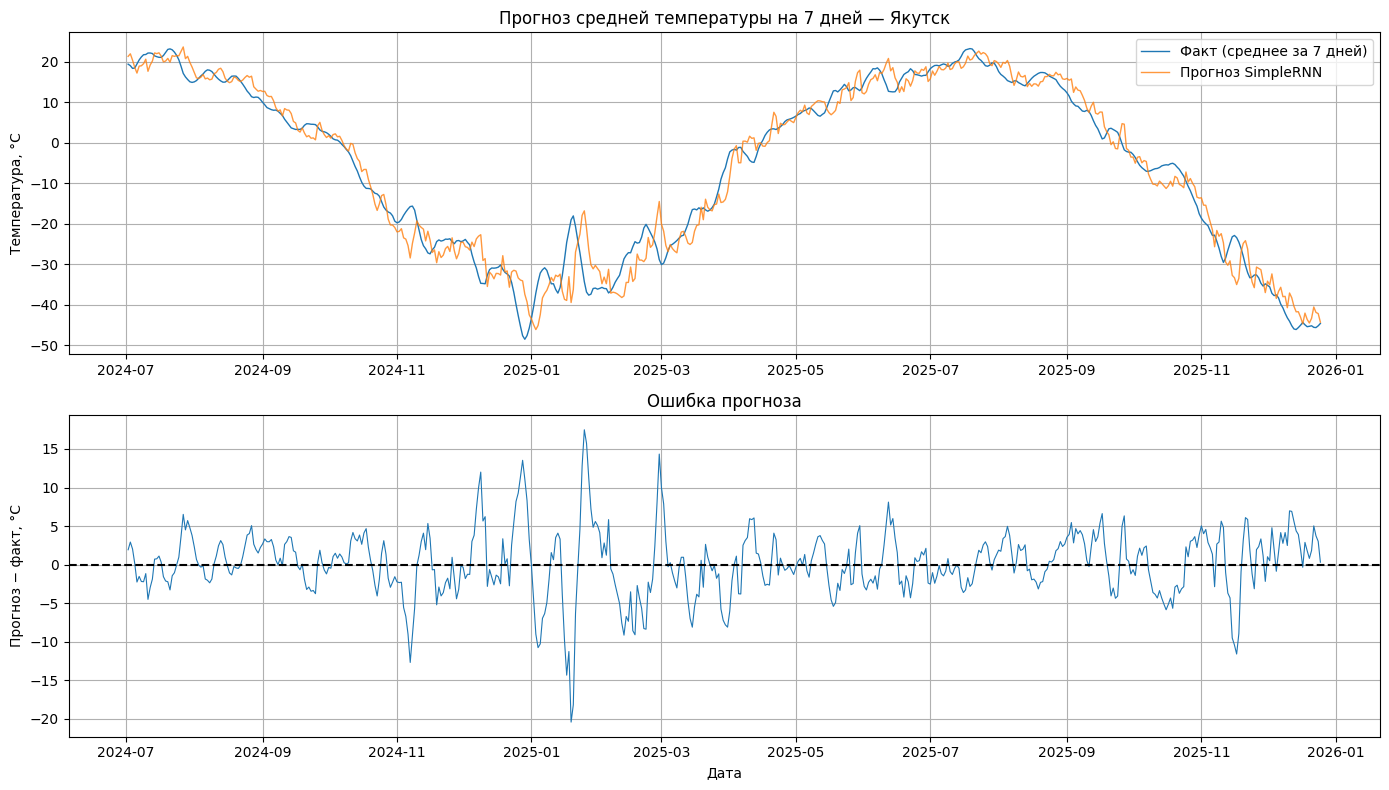

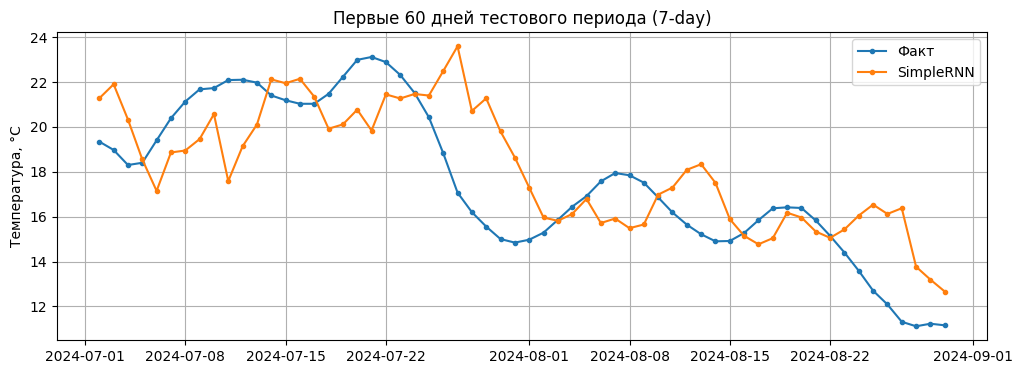

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(
    test_dates_7day,
    actual_7day,
    label="Факт (среднее за 7 дней)",
    linewidth=1,
)
axes[0].plot(
    test_dates_7day,
    predictions_7day[winner_7day],
    label=f"Прогноз {winner_7day}",
    linewidth=1,
    alpha=0.8,
)
axes[0].set_title(f"Прогноз средней температуры на 7 дней — {CITY}")
axes[0].set_ylabel("Температура, °C")
axes[0].legend()

errors_7day = predictions_7day[winner_7day] - actual_7day
axes[1].plot(test_dates_7day, errors_7day, linewidth=0.8)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Ошибка прогноза")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Прогноз − факт, °C")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(test_dates_7day[:60], actual_7day[:60], label="Факт", marker=".")
plt.plot(
    test_dates_7day[:60],
    predictions_7day[winner_7day][:60],
    label=winner_7day,
    marker=".",
)
plt.title("Первые 60 дней тестового периода (7-day)")
plt.ylabel("Температура, °C")
plt.legend()
plt.show()

**Верхний график** показывает прогноз модели SimpleRNN на всём тестовом периоде (июль 2024 — январь 2026). Модель корректно воспроизводит годовой сезонный цикл Якутска: летние максимумы около +20°C и зимние минимумы около −45°C. Ошибка прогноза в большинстве случаев находится в диапазоне ±5°C, что для недельного горизонта является хорошим результатом. Однако в периоды резких температурных перепадов (ноябрь 2024, январь 2025, март 2025, ноябрь 2025) наблюдаются выбросы ошибки до ±15–20°C — модель не успевает адаптироваться к быстрым изменениям погоды, характерным для резко континентального климата.

**Нижний график** детализирует первые 60 дней тестового периода (июль–август 2024). Здесь хорошо видно, что модель иногда запаздывает в реакции на резкие изменения температуры: например, в конце июля фактическая температура быстро снижается, а прогноз следует за ней с задержкой в 1–2 дня. Это типичное поведение рекуррентных сетей при работе с нестационарными временными рядами.

**Общий вывод:** модель SimpleRNN демонстрирует высокое качество прогноза недельного среднего (R² = 0.959), хорошо улавливает сезонность, но имеет ограничения при прогнозировании резких температурных скачков.

### 9.Сохранение результатов

``encoding="utf-8-sig"`` — для корректного открытия CSV в Excel с кириллицей.

Сохраняем: таблицу экспериментов, метрик и полные прогнозы. Это обеспечивает воспроизводимость.

In [11]:
experiment_table_7day.to_csv(
    "experiments_7day.csv",
    index=False,
    encoding="utf-8-sig",
)

result_table_7day.to_csv(
    "metrics_7day.csv",
    encoding="utf-8-sig",
)

forecast_table_7day = pd.DataFrame(
    {
        "Дата": test_dates_7day,
        "Факт (среднее за 7 дней)": actual_7day,
        **predictions_7day,
    }
)

forecast_table_7day.to_csv(
    "predictions_7day.csv",
    index=False,
    encoding="utf-8-sig",
)

print("Таблицы экспериментов, метрик и прогнозов сохранены.")

Таблицы экспериментов, метрик и прогнозов сохранены.


### 10. Ответы на контрольные вопросы

Ответы на вопросы 1 - 13 находятся в блокноте задачи А. Ответы на вопросы 14-25 в блокноте задачи B.

14. **Что такое Dropout и как он помогает бороться с переобучением?**
Dropout — техника регуляризации, при которой во время обучения случайным образом «отключается» (обнуляется) доля нейронов с вероятностью p. Это предотвращает ко-адаптацию нейронов; заставляет сеть учить более робастные признаки; действует как ансамбль из множества подсетей.
15. **Как работает EarlyStopping и зачем восстанавливать лучшие веса?**
EarlyStopping отслеживает validation loss после каждой эпохи. Если loss не улучшается в течение patience эпох — обучение останавливается. restore_best_weights=True возвращает веса модели к моменту наилучшего validation loss, а не к моменту остановки. Это защищает от переобучения в конце обучения.
16. **Какую функцию потерь и выходную активацию целесообразно использовать для регрессии температуры?**
Функция потерь: MSE (среднеквадратичная ошибка) — стандартный выбор для регрессии, сильно штрафует крупные выбросы. Альтернативы: MAE, Huber loss.
Выходная активация: linear (линейная), так как температура — непрерывная величина, не ограниченная диапазоном [0, 1].
17. **Что характеризуют MSE, MAE и RMSE? В каких единицах измеряется каждая метрика?**
MAE (Mean Absolute Error) — средняя абсолютная ошибка, в °C. Интерпретируется как «в среднем модель ошибается на X градусов».
MSE (Mean Squared Error) — средний квадрат ошибки, в °C². Сильнее штрафует крупные отклонения.
RMSE (Root MSE) — корень из MSE, в °C. Более интерпретируемая мера крупных ошибок.
18. **Как интерпретировать R², включая отрицательное значение?**
R² — доля дисперсии целевой переменной, объяснённая моделью:
* R² = 1 — идеальное предсказание;
* R² = 0 — модель не лучше, чем предсказание средним значением;
* R² < 0 — модель хуже, чем предсказание средним (серьёзная проблема).
Ориентир для хорошей модели: R² ≥ 0.80.
19. **Почему нейросетевую модель необходимо сравнивать с наивным прогнозом?**
Наивный прогноз (persistence, seasonal naive) — это минимальный baseline. Если нейросеть не превосходит его, значит:
* модель не уловила полезные паттерны;
* задача слишком проста для сложной модели;
* есть проблемы с данными или обучением.
Без baseline нельзя оценить реальную пользу модели.
20. **Как определить, что модель переобучилась, по графикам training loss и validation loss?**
Признаки переобучения:
* training loss продолжает снижаться, а validation loss растёт или выходит на плато;
* разрыв между кривыми train и val увеличивается со временем;
* val loss значительно выше train loss.
Норма: обе кривые снижаются и сходятся к близким значениям.
21. **Почему прогноз недельного среднего является задачей с горизонтом семь дней?**
Целевая переменная y(t) = mean(T(t), ..., T(t+6)) использует семь будущих значений. Модель должна «заглянуть» на 7 дней вперёд, чтобы вычислить среднее. Это принципиально отличается от прогноза на 1 день, где горизонт = 1.
22. **Чем отличается прогноз средней температуры за следующие семь дней от прогноза семи отдельных дневных температур?**
Прогноз среднего — модель выдаёт одно скалярное значение (среднее за 7 дней). Это сглаживает шум, задача проще, метрики обычно лучше.
Прогноз 7 отдельных дней — модель выдаёт вектор из 7 значений. Требует более сложной архитектуры (multi-output), накапливает ошибку на каждом шаге, сложнее оценивать.
В нашем случае используется первый подход — одно число на каждое t.
23. **Почему при сравнении моделей необходимо использовать одинаковые тестовые даты?**
Разные длины окна L дают разные наборы тестовых примеров (разные стартовые индексы). Чтобы сравнение было честным, все модели должны оцениваться на одном и том же множестве тестовых дат. Иначе разница в метриках может быть вызвана не качеством модели, а различиями в тестовых периодах.
24. **Какие дополнительные признаки погоды могут улучшить прогноз и какие риски возникают при их использовании?**
Дополнительные признаки: минимальная/максимальная температура, осадки, скорость ветра, влажность, давление.
Плюсы: больше информации → потенциально лучший прогноз.
Риски:
* нужны прогнозы этих признаков на будущие даты (иначе утечка);
* увеличение размерности → риск переобучения;
* пропуски и шум в дополнительных признаках.
25. **Какие параметры эксперимента необходимо зафиксировать для воспроизводимости?**
Random seed (numpy, tensorflow, python); Точные даты train/validation/test; Архитектуры моделей (число слоёв, нейронов, активации); Гиперпараметры: learning rate, batch size, число эпох, patience EarlyStopping; Параметры масштабирования (mean, std от train); Источник и период данных.